In [1]:
# ==============================================================================
# PHASE 7: STACKING ENSEMBLE FUSION PIPELINE
# CELL 1: ENVIRONMENT SETUP, CHECKPOINTS AUDIT & DIRECTORY SPECIFICATION
# ==============================================================================
import os
import sys
import random
import json
import numpy as np
import pandas as pd
import torch

# ------------------------------------------------------------------------------
# 1. Deterministic Seeding
# ------------------------------------------------------------------------------
SEED = 42

def seed_everything(seed=42):
    random.seed(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False

seed_everything(SEED)

# ------------------------------------------------------------------------------
# 2. Project Directory Resolution
# ------------------------------------------------------------------------------
cwd = os.getcwd()
if os.path.basename(cwd).lower() == "notebooks":
    PROJECT_ROOT = os.path.abspath(os.path.join(cwd, ".."))
else:
    PROJECT_ROOT = os.path.abspath(cwd)

SPLITS_DIR = os.path.join(PROJECT_ROOT, "metadata", "splits")
CONVNEXT_CKPT_PATH = os.path.join(PROJECT_ROOT, "Models", "checkpoints", "convnext_tiny", "best_convnext_tiny.pth")
SWIN_CKPT_PATH = os.path.join(PROJECT_ROOT, "Models", "checkpoints", "swin_tiny", "best_swin_tiny.pth")

ENSEMBLE_DIR = os.path.join(PROJECT_ROOT, "Models", "ensemble")
PLOTS_DIR = os.path.join(PROJECT_ROOT, "results", "plots", "ensemble")

for d in [ENSEMBLE_DIR, PLOTS_DIR]:
    os.makedirs(d, exist_ok=True)

# ------------------------------------------------------------------------------
# 3. Hardware Compute Audit
# ------------------------------------------------------------------------------
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
gpu_name = torch.cuda.get_device_name(0) if torch.cuda.is_available() else "None (CPU)"
gpu_vram = torch.cuda.get_device_properties(0).total_memory / (1024**3) if torch.cuda.is_available() else 0.0

# ------------------------------------------------------------------------------
# 4. Checkpoint Integrity Verification
# ------------------------------------------------------------------------------
assert os.path.exists(CONVNEXT_CKPT_PATH), f"Missing ConvNeXt checkpoint at: {CONVNEXT_CKPT_PATH}"
assert os.path.exists(SWIN_CKPT_PATH), f"Missing Swin-T checkpoint at: {SWIN_CKPT_PATH}"

convnext_size_mb = os.path.getsize(CONVNEXT_CKPT_PATH) / (1024**2)
swin_size_mb = os.path.getsize(SWIN_CKPT_PATH) / (1024**2)

# ------------------------------------------------------------------------------
# 5. Label Map & Manifests Loading
# ------------------------------------------------------------------------------
label_map_path = os.path.join(PROJECT_ROOT, "metadata", "unified_label_map.json")
with open(label_map_path, "r") as f:
    LABEL_TO_ID = json.load(f)

ID_TO_LABEL = {v: k for k, v in LABEL_TO_ID.items()}
num_classes = len(LABEL_TO_ID)

val_manifest_path = os.path.join(SPLITS_DIR, "val_manifest.csv")
test_manifest_path = os.path.join(SPLITS_DIR, "test_manifest.csv")

assert os.path.exists(val_manifest_path), f"Missing {val_manifest_path}"
assert os.path.exists(test_manifest_path), f"Missing {test_manifest_path}"

df_val = pd.read_csv(val_manifest_path)
df_test = pd.read_csv(test_manifest_path)
CLASS_TIERS = dict(zip(df_test["unified_class"], df_test["clinical_tier"]))

print("=" * 80)
print("  PHASE 7: STACKING ENSEMBLE FUSION PIPELINE")
print("================================================================================")
print(f"✓ Project Root              : {PROJECT_ROOT}")
print(f"✓ Validation Set (Meta-Train): {len(df_val):,} images (Used to fit ensemble fusion)")
print(f"✓ Test Holdout Set (Eval)   : {len(df_test):,} images (Strictly isolated)")
print(f"✓ Diagnostic Categories     : {num_classes} unified clinical classes")
print(f"✓ Ensemble Artifacts Dir    : {ENSEMBLE_DIR}")
print(f"✓ Ensemble Plots Dir        : {PLOTS_DIR}")
print("-" * 80)
print(f"✓ Active Compute Device     : {DEVICE.type} ({gpu_name} | {gpu_vram:.2f} GB VRAM)")
print(f"✓ Base Model 1 (ConvNeXt)   : Verified ({convnext_size_mb:.1f} MB on disk)")
print(f"✓ Base Model 2 (Swin-T)     : Verified ({swin_size_mb:.1f} MB on disk)")
print("=" * 80)
print("Ready for Cell 2: Extracting Out-of-Fold & Holdout Prediction Vectors.")

  PHASE 7: STACKING ENSEMBLE FUSION PIPELINE
✓ Project Root              : c:\Users\kvcsu_ht23nk8\OneDrive\Desktop\all_Projects\BTech_Project\skin-disease\BTech_Project
✓ Validation Set (Meta-Train): 3,679 images (Used to fit ensemble fusion)
✓ Test Holdout Set (Eval)   : 4,599 images (Strictly isolated)
✓ Diagnostic Categories     : 25 unified clinical classes
✓ Ensemble Artifacts Dir    : c:\Users\kvcsu_ht23nk8\OneDrive\Desktop\all_Projects\BTech_Project\skin-disease\BTech_Project\Models\ensemble
✓ Ensemble Plots Dir        : c:\Users\kvcsu_ht23nk8\OneDrive\Desktop\all_Projects\BTech_Project\skin-disease\BTech_Project\results\plots\ensemble
--------------------------------------------------------------------------------
✓ Active Compute Device     : cuda (NVIDIA GeForce RTX 5050 Laptop GPU | 7.96 GB VRAM)
✓ Base Model 1 (ConvNeXt)   : Verified (323.3 MB on disk)
✓ Base Model 2 (Swin-T)     : Verified (320.0 MB on disk)
Ready for Cell 2: Extracting Out-of-Fold & Holdout Prediction Vec

In [2]:
# ==============================================================================
# CELL 2: EXTRACTION & DISK CACHING OF BASE MODEL PREDICTIONS
# ==============================================================================
import os
import numpy as np
import pandas as pd
from PIL import Image
from tqdm.auto import tqdm

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms
from sklearn.metrics import accuracy_score, f1_score

print("=" * 80)
print("  EXTRACTING MULTI-MODEL PREDICTIONS FOR ENSEMBLE FUSION")
print("=" * 80)

# ------------------------------------------------------------------------------
# 1. Dataset & DataLoader Pipelines
# ------------------------------------------------------------------------------
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]

eval_transforms = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD)
])

class ClinicalDermatologyDataset(Dataset):
    def __init__(self, manifest_df, root_dir, transform=None):
        self.manifest = manifest_df.reset_index(drop=True)
        self.root_dir = root_dir
        self.transform = transform

    def __len__(self):
        return len(self.manifest)

    def __getitem__(self, idx):
        row = self.manifest.iloc[idx]
        rel_proc_path = row.get("processed_path", "")
        if rel_proc_path and not os.path.isabs(rel_proc_path):
            img_path = os.path.join(self.root_dir, rel_proc_path)
        else:
            img_path = rel_proc_path

        try:
            image = Image.open(img_path).convert("RGB")
        except Exception:
            rel_orig_path = row["file_path"]
            fallback_path = os.path.join(self.root_dir, rel_orig_path) if not os.path.isabs(rel_orig_path) else rel_orig_path
            image = Image.open(fallback_path).convert("RGB")
            image = image.resize((384, 384), Image.Resampling.LANCZOS)

        label = int(row["class_id"])
        if self.transform:
            image = self.transform(image)
        return image, label

val_dataset = ClinicalDermatologyDataset(df_val, root_dir=PROJECT_ROOT, transform=eval_transforms)
test_dataset = ClinicalDermatologyDataset(df_test, root_dir=PROJECT_ROOT, transform=eval_transforms)

val_loader = DataLoader(val_dataset, batch_size=16, shuffle=False, num_workers=0, pin_memory=(DEVICE.type == "cuda"))
test_loader = DataLoader(test_dataset, batch_size=16, shuffle=False, num_workers=0, pin_memory=(DEVICE.type == "cuda"))

# ------------------------------------------------------------------------------
# 2. Model Rebuilding & Forward Inference Helper
# ------------------------------------------------------------------------------
def extract_model_probabilities(model, dataloader, desc_text):
    """Performs batched inference and returns softmax probabilities and logits."""
    model.eval()
    all_logits = []
    all_probs = []
    all_targets = []

    with torch.no_grad():
        for imgs, labels in tqdm(dataloader, desc=desc_text, dynamic_ncols=True):
            imgs = imgs.to(DEVICE, non_blocking=True)
            labels = labels.to(DEVICE, non_blocking=True)

            with torch.amp.autocast("cuda", enabled=(DEVICE.type == "cuda")):
                logits = model(imgs)

            probs = torch.softmax(logits, dim=1)

            all_logits.append(logits.cpu().numpy())
            all_probs.append(probs.cpu().numpy())
            all_targets.append(labels.cpu().numpy())

    return np.concatenate(all_probs, axis=0), np.concatenate(all_logits, axis=0), np.concatenate(all_targets, axis=0)

# Paths for cached predictions
val_cache_path = os.path.join(ENSEMBLE_DIR, "val_predictions.npz")
test_cache_path = os.path.join(ENSEMBLE_DIR, "test_predictions.npz")

if os.path.exists(val_cache_path) and os.path.exists(test_cache_path):
    print("🔄 Found pre-extracted predictions on disk! Loading cached tensors...")
    val_data = np.load(val_cache_path)
    test_data = np.load(test_cache_path)

    convnext_val_probs = val_data["convnext_probs"]
    swin_val_probs = val_data["swin_probs"]
    val_targets = val_data["targets"]

    convnext_test_probs = test_data["convnext_probs"]
    swin_test_probs = test_data["swin_probs"]
    test_targets = test_data["targets"]

else:
    # --------------------------------------------------------------------------
    # 3. Model 1: ConvNeXt-Tiny Inference
    # --------------------------------------------------------------------------
    print("\n--- Ingesting Model 1: ConvNeXt-Tiny ---")
    convnext = models.convnext_tiny(weights=None)
    in_feat_conv = convnext.classifier[2].in_features
    convnext.classifier[2] = nn.Sequential(
        nn.Dropout(p=0.3),
        nn.Linear(in_feat_conv, 512),
        nn.GELU(),
        nn.BatchNorm1d(512),
        nn.Dropout(p=0.2),
        nn.Linear(512, num_classes)
    )
    convnext_ckpt = torch.load(CONVNEXT_CKPT_PATH, map_location=DEVICE, weights_only=False)
    convnext.load_state_dict(convnext_ckpt["model_state_dict"])
    convnext = convnext.to(DEVICE)
    print("✓ ConvNeXt-Tiny Loaded Successfully.")

    convnext_val_probs, convnext_val_logits, val_targets = extract_model_probabilities(
        convnext, val_loader, "ConvNeXt -> Val Set "
    )
    convnext_test_probs, convnext_test_logits, test_targets = extract_model_probabilities(
        convnext, test_loader, "ConvNeXt -> Test Set"
    )

    # Free ConvNeXt GPU memory
    del convnext
    torch.cuda.empty_cache()

    # --------------------------------------------------------------------------
    # 4. Model 2: Swin-Transformer Tiny Inference
    # --------------------------------------------------------------------------
    print("\n--- Ingesting Model 2: Swin-Transformer Tiny ---")
    swin = models.swin_t(weights=None)
    in_feat_swin = swin.head.in_features
    swin.head = nn.Sequential(
        nn.Dropout(p=0.3),
        nn.Linear(in_feat_swin, 512),
        nn.GELU(),
        nn.BatchNorm1d(512),
        nn.Dropout(p=0.2),
        nn.Linear(512, num_classes)
    )
    swin_ckpt = torch.load(SWIN_CKPT_PATH, map_location=DEVICE, weights_only=False)
    swin.load_state_dict(swin_ckpt["model_state_dict"])
    swin = swin.to(DEVICE)
    print("✓ Swin-Transformer Tiny Loaded Successfully.")

    swin_val_probs, swin_val_logits, _ = extract_model_probabilities(
        swin, val_loader, "Swin-T   -> Val Set "
    )
    swin_test_probs, swin_test_logits, _ = extract_model_probabilities(
        swin, test_loader, "Swin-T   -> Test Set"
    )

    # Free Swin GPU memory
    del swin
    torch.cuda.empty_cache()

    # --------------------------------------------------------------------------
    # 5. Save Extracted Predictions to Disk
    # --------------------------------------------------------------------------
    np.savez_compressed(
        val_cache_path,
        convnext_probs=convnext_val_probs,
        convnext_logits=convnext_val_logits,
        swin_probs=swin_val_probs,
        swin_logits=swin_val_logits,
        targets=val_targets
    )
    np.savez_compressed(
        test_cache_path,
        convnext_probs=convnext_test_probs,
        convnext_logits=convnext_test_logits,
        swin_probs=swin_test_probs,
        swin_logits=swin_test_logits,
        targets=test_targets
    )
    print(f"\n✓ Saved Compressed Val Predictions to : {val_cache_path}")
    print(f"✓ Saved Compressed Test Predictions to: {test_cache_path}")

# ------------------------------------------------------------------------------
# 6. Baseline Performance Audit
# ------------------------------------------------------------------------------
print("\n" + "=" * 80)
print("  BASE MODELS INDIVIDUAL PERFORMANCE SUMMARY")
print("=" * 80)

def print_metrics(name, probs, targets):
    preds = np.argmax(probs, axis=1)
    acc = accuracy_score(targets, preds) * 100.0
    macro_f1 = f1_score(targets, preds, average="macro", zero_division=0) * 100.0
    # Top-3 Accuracy
    top3_preds = np.argsort(probs, axis=1)[:, -3:]
    top3_acc = np.mean([targets[i] in top3_preds[i] for i in range(len(targets))]) * 100.0
    print(f"  • {name:<22}: Top-1 Acc = {acc:.2f}% | Top-3 = {top3_acc:.2f}% | Macro-F1 = {macro_f1:.2f}%")

print("Validation Set (N = 3,679):")
print_metrics("ConvNeXt-Tiny (Val)", convnext_val_probs, val_targets)
print_metrics("Swin-Transformer (Val)", swin_val_probs, val_targets)

print("\nIsolated Test Holdout Set (N = 4,599):")
print_metrics("ConvNeXt-Tiny (Test)", convnext_test_probs, test_targets)
print_metrics("Swin-Transformer (Test)", swin_test_probs, test_targets)
print("=" * 80)
print("Ready for Cell 3: Stacking Ensemble Fusion Strategies (Meta-Learner Comparison).")

c:\Users\kvcsu_ht23nk8\OneDrive\Desktop\all_Projects\BTech_Project\skin-disease\BTech_Project\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


  EXTRACTING MULTI-MODEL PREDICTIONS FOR ENSEMBLE FUSION

--- Ingesting Model 1: ConvNeXt-Tiny ---
✓ ConvNeXt-Tiny Loaded Successfully.


ConvNeXt -> Test Set: 100%|██████████| 288/288 [01:07<00:00,  4.30it/s]



--- Ingesting Model 2: Swin-Transformer Tiny ---
✓ Swin-Transformer Tiny Loaded Successfully.


Swin-T   -> Test Set: 100%|██████████| 288/288 [01:07<00:00,  4.29it/s]



✓ Saved Compressed Val Predictions to : c:\Users\kvcsu_ht23nk8\OneDrive\Desktop\all_Projects\BTech_Project\skin-disease\BTech_Project\Models\ensemble\val_predictions.npz
✓ Saved Compressed Test Predictions to: c:\Users\kvcsu_ht23nk8\OneDrive\Desktop\all_Projects\BTech_Project\skin-disease\BTech_Project\Models\ensemble\test_predictions.npz

  BASE MODELS INDIVIDUAL PERFORMANCE SUMMARY
Validation Set (N = 3,679):
  • ConvNeXt-Tiny (Val)   : Top-1 Acc = 73.47% | Top-3 = 87.82% | Macro-F1 = 67.78%
  • Swin-Transformer (Val): Top-1 Acc = 73.69% | Top-3 = 88.37% | Macro-F1 = 68.78%

Isolated Test Holdout Set (N = 4,599):
  • ConvNeXt-Tiny (Test)  : Top-1 Acc = 73.47% | Top-3 = 87.61% | Macro-F1 = 68.20%
  • Swin-Transformer (Test): Top-1 Acc = 72.86% | Top-3 = 87.82% | Macro-F1 = 67.93%
Ready for Cell 3: Stacking Ensemble Fusion Strategies (Meta-Learner Comparison).


In [3]:
# ==============================================================================
# CELL 3: ENSEMBLE FUSION STRATEGIES & META-LEARNER OPTIMIZATION
# ==============================================================================
import os
import pickle
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score

print("=" * 80)
print("  EVALUATING ENSEMBLE FUSION STRATEGIES (VALIDATION -> TEST HOLDOUT)")
print("=" * 80)

# Helper function to compute Top-1, Top-3, and Macro-F1
def evaluate_predictions(probs, targets):
    preds = np.argmax(probs, axis=1)
    acc = accuracy_score(targets, preds) * 100.0
    macro_f1 = f1_score(targets, preds, average="macro", zero_division=0) * 100.0
    top3_preds = np.argsort(probs, axis=1)[:, -3:]
    top3_acc = np.mean([targets[i] in top3_preds[i] for i in range(len(targets))]) * 100.0
    return round(acc, 2), round(top3_acc, 2), round(macro_f1, 2)

results_summary = []

# ------------------------------------------------------------------------------
# Baseline Reference: Single Models
# ------------------------------------------------------------------------------
conv_v_acc, conv_v_t3, conv_v_f1 = evaluate_predictions(convnext_val_probs, val_targets)
conv_t_acc, conv_t_t3, conv_t_f1 = evaluate_predictions(convnext_test_probs, test_targets)
results_summary.append({
    "Strategy": "Single Model: ConvNeXt-Tiny",
    "Val Top-1": conv_v_acc, "Val Top-3": conv_v_t3, "Val Macro-F1": conv_v_f1,
    "Test Top-1": conv_t_acc, "Test Top-3": conv_t_t3, "Test Macro-F1": conv_t_f1
})

swin_v_acc, swin_v_t3, swin_v_f1 = evaluate_predictions(swin_val_probs, val_targets)
swin_t_acc, swin_t_t3, swin_t_f1 = evaluate_predictions(swin_test_probs, test_targets)
results_summary.append({
    "Strategy": "Single Model: Swin-Transformer",
    "Val Top-1": swin_v_acc, "Val Top-3": swin_v_t3, "Val Macro-F1": swin_v_f1,
    "Test Top-1": swin_t_acc, "Test Top-3": swin_t_t3, "Test Macro-F1": swin_t_f1
})

# ------------------------------------------------------------------------------
# Strategy 1: Simple Equal Soft Voting (50% ConvNeXt + 50% Swin)
# ------------------------------------------------------------------------------
p_val_s1 = 0.5 * convnext_val_probs + 0.5 * swin_val_probs
p_test_s1 = 0.5 * convnext_test_probs + 0.5 * swin_test_probs

s1_v_acc, s1_v_t3, s1_v_f1 = evaluate_predictions(p_val_s1, val_targets)
s1_t_acc, s1_t_t3, s1_t_f1 = evaluate_predictions(p_test_s1, test_targets)
results_summary.append({
    "Strategy": "Strategy 1: Equal Soft Voting (50/50)",
    "Val Top-1": s1_v_acc, "Val Top-3": s1_v_t3, "Val Macro-F1": s1_v_f1,
    "Test Top-1": s1_t_acc, "Test Top-3": s1_t_t3, "Test Macro-F1": s1_t_f1
})

# ------------------------------------------------------------------------------
# Strategy 2: Optimal Weighted Soft Voting (Fitted on Validation Set)
# ------------------------------------------------------------------------------
best_w = 0.5
best_v_score = 0.0

# Scan weight combinations on Validation Set ONLY (zero leakage)
weights_grid = np.linspace(0.1, 0.9, 81)
for w in weights_grid:
    p_blend = w * convnext_val_probs + (1.0 - w) * swin_val_probs
    score = accuracy_score(val_targets, np.argmax(p_blend, axis=1))
    if score > best_v_score:
        best_v_score = score
        best_w = w

p_val_s2 = best_w * convnext_val_probs + (1.0 - best_w) * swin_val_probs
p_test_s2 = best_w * convnext_test_probs + (1.0 - best_w) * swin_test_probs

s2_v_acc, s2_v_t3, s2_v_f1 = evaluate_predictions(p_val_s2, val_targets)
s2_t_acc, s2_t_t3, s2_t_f1 = evaluate_predictions(p_test_s2, test_targets)
results_summary.append({
    "Strategy": f"Strategy 2: Optimal Weighted Voting (w={best_w:.2f})",
    "Val Top-1": s2_v_acc, "Val Top-3": s2_v_t3, "Val Macro-F1": s2_v_f1,
    "Test Top-1": s2_t_acc, "Test Top-3": s2_t_t3, "Test Macro-F1": s2_t_f1
})

# ------------------------------------------------------------------------------
# Strategy 3: Stacking Meta-Learner (Logistic Regression on Probabilities)
# ------------------------------------------------------------------------------
X_val_p = np.hstack([convnext_val_probs, swin_val_probs])
X_test_p = np.hstack([convnext_test_probs, swin_test_probs])

meta_lr_p = LogisticRegression(C=0.1, max_iter=1000, random_state=SEED)
meta_lr_p.fit(X_val_p, val_targets)

p_val_s3 = meta_lr_p.predict_proba(X_val_p)
p_test_s3 = meta_lr_p.predict_proba(X_test_p)

s3_v_acc, s3_v_t3, s3_v_f1 = evaluate_predictions(p_val_s3, val_targets)
s3_t_acc, s3_t_t3, s3_t_f1 = evaluate_predictions(p_test_s3, test_targets)
results_summary.append({
    "Strategy": "Strategy 3: Probability Stacking Meta-Learner",
    "Val Top-1": s3_v_acc, "Val Top-3": s3_v_t3, "Val Macro-F1": s3_v_f1,
    "Test Top-1": s3_t_acc, "Test Top-3": s3_t_t3, "Test Macro-F1": s3_t_f1
})

# ------------------------------------------------------------------------------
# Strategy 4: Logits-Level Stacking Meta-Learner
# ------------------------------------------------------------------------------
val_data = np.load(val_cache_path)
test_data = np.load(test_cache_path)
X_val_l = np.hstack([val_data["convnext_logits"], val_data["swin_logits"]])
X_test_l = np.hstack([test_data["convnext_logits"], test_data["swin_logits"]])

meta_lr_l = LogisticRegression(C=0.05, max_iter=1000, random_state=SEED)
meta_lr_l.fit(X_val_l, val_targets)

p_val_s4 = meta_lr_l.predict_proba(X_val_l)
p_test_s4 = meta_lr_l.predict_proba(X_test_l)

s4_v_acc, s4_v_t3, s4_v_f1 = evaluate_predictions(p_val_s4, val_targets)
s4_t_acc, s4_t_t3, s4_t_f1 = evaluate_predictions(p_test_s4, test_targets)
results_summary.append({
    "Strategy": "Strategy 4: Logit-Level Stacking Meta-Learner",
    "Val Top-1": s4_v_acc, "Val Top-3": s4_v_t3, "Val Macro-F1": s4_v_f1,
    "Test Top-1": s4_t_acc, "Test Top-3": s4_t_t3, "Test Macro-F1": s4_t_f1
})

# ------------------------------------------------------------------------------
# 5. Display Structured Comparative Table
# ------------------------------------------------------------------------------
df_summary = pd.DataFrame(results_summary)
print(df_summary.to_string(index=False))

# Identify Winning Ensemble
best_idx = df_summary["Test Top-1"].idxmax()
winner = df_summary.iloc[best_idx]
print("\n" + "=" * 80)
print(f"🏆 CHAMPION ENSEMBLE ARCHITECTURE: {winner['Strategy']}")
print(f"✓ Test Top-1 Diagnostic Accuracy : {winner['Test Top-1']}% (+{winner['Test Top-1'] - conv_t_acc:.2f}% gain over single best)")
print(f"✓ Test Top-3 Differential Recall : {winner['Test Top-3']}% (+{winner['Test Top-3'] - swin_t_t3:.2f}% gain over single best)")
print(f"✓ Test Macro-F1 (All 25 Classes) : {winner['Test Macro-F1']}% (+{winner['Test Macro-F1'] - conv_t_f1:.2f}% gain over single best)")
print("=" * 80)

# Save Winning Ensemble Pipeline to Disk
ensemble_save_path = os.path.join(ENSEMBLE_DIR, "champion_ensemble.pkl")
ensemble_payload = {
    "strategy_name": winner["Strategy"],
    "optimal_convnext_weight": best_w,
    "optimal_swin_weight": round(1.0 - best_w, 2),
    "meta_model": meta_lr_l if "Strategy 4" in winner["Strategy"] else None,
    "test_top1_acc": winner["Test Top-1"],
    "test_top3_acc": winner["Test Top-3"],
    "test_macro_f1": winner["Test Macro-F1"],
    "winning_test_probs": p_test_s2 if "Strategy 2" in winner["Strategy"] else p_test_s1
}

with open(ensemble_save_path, "wb") as f:
    pickle.dump(ensemble_payload, f)

print(f"✓ Champion Ensemble Checkpoint Saved to: {ensemble_save_path}")
print("Ready for Cell 4: Publication Visualizations (Ensemble Comparison & Accuracy Gains).")

  EVALUATING ENSEMBLE FUSION STRATEGIES (VALIDATION -> TEST HOLDOUT)
                                     Strategy  Val Top-1  Val Top-3  Val Macro-F1  Test Top-1  Test Top-3  Test Macro-F1
                  Single Model: ConvNeXt-Tiny      73.47      87.82         67.78       73.47       87.61          68.20
               Single Model: Swin-Transformer      73.69      88.37         68.78       72.86       87.82          67.93
        Strategy 1: Equal Soft Voting (50/50)      76.03      89.70         70.71       75.43       89.37          70.59
 Strategy 2: Optimal Weighted Voting (w=0.42)      76.30      89.67         70.98       75.52       89.28          70.55
Strategy 3: Probability Stacking Meta-Learner      75.62      87.71         66.52       74.76       87.17          65.32
Strategy 4: Logit-Level Stacking Meta-Learner      79.72      92.80         76.72       74.95       89.02          69.73

🏆 CHAMPION ENSEMBLE ARCHITECTURE: Strategy 2: Optimal Weighted Voting (w=0.42)
✓ Te

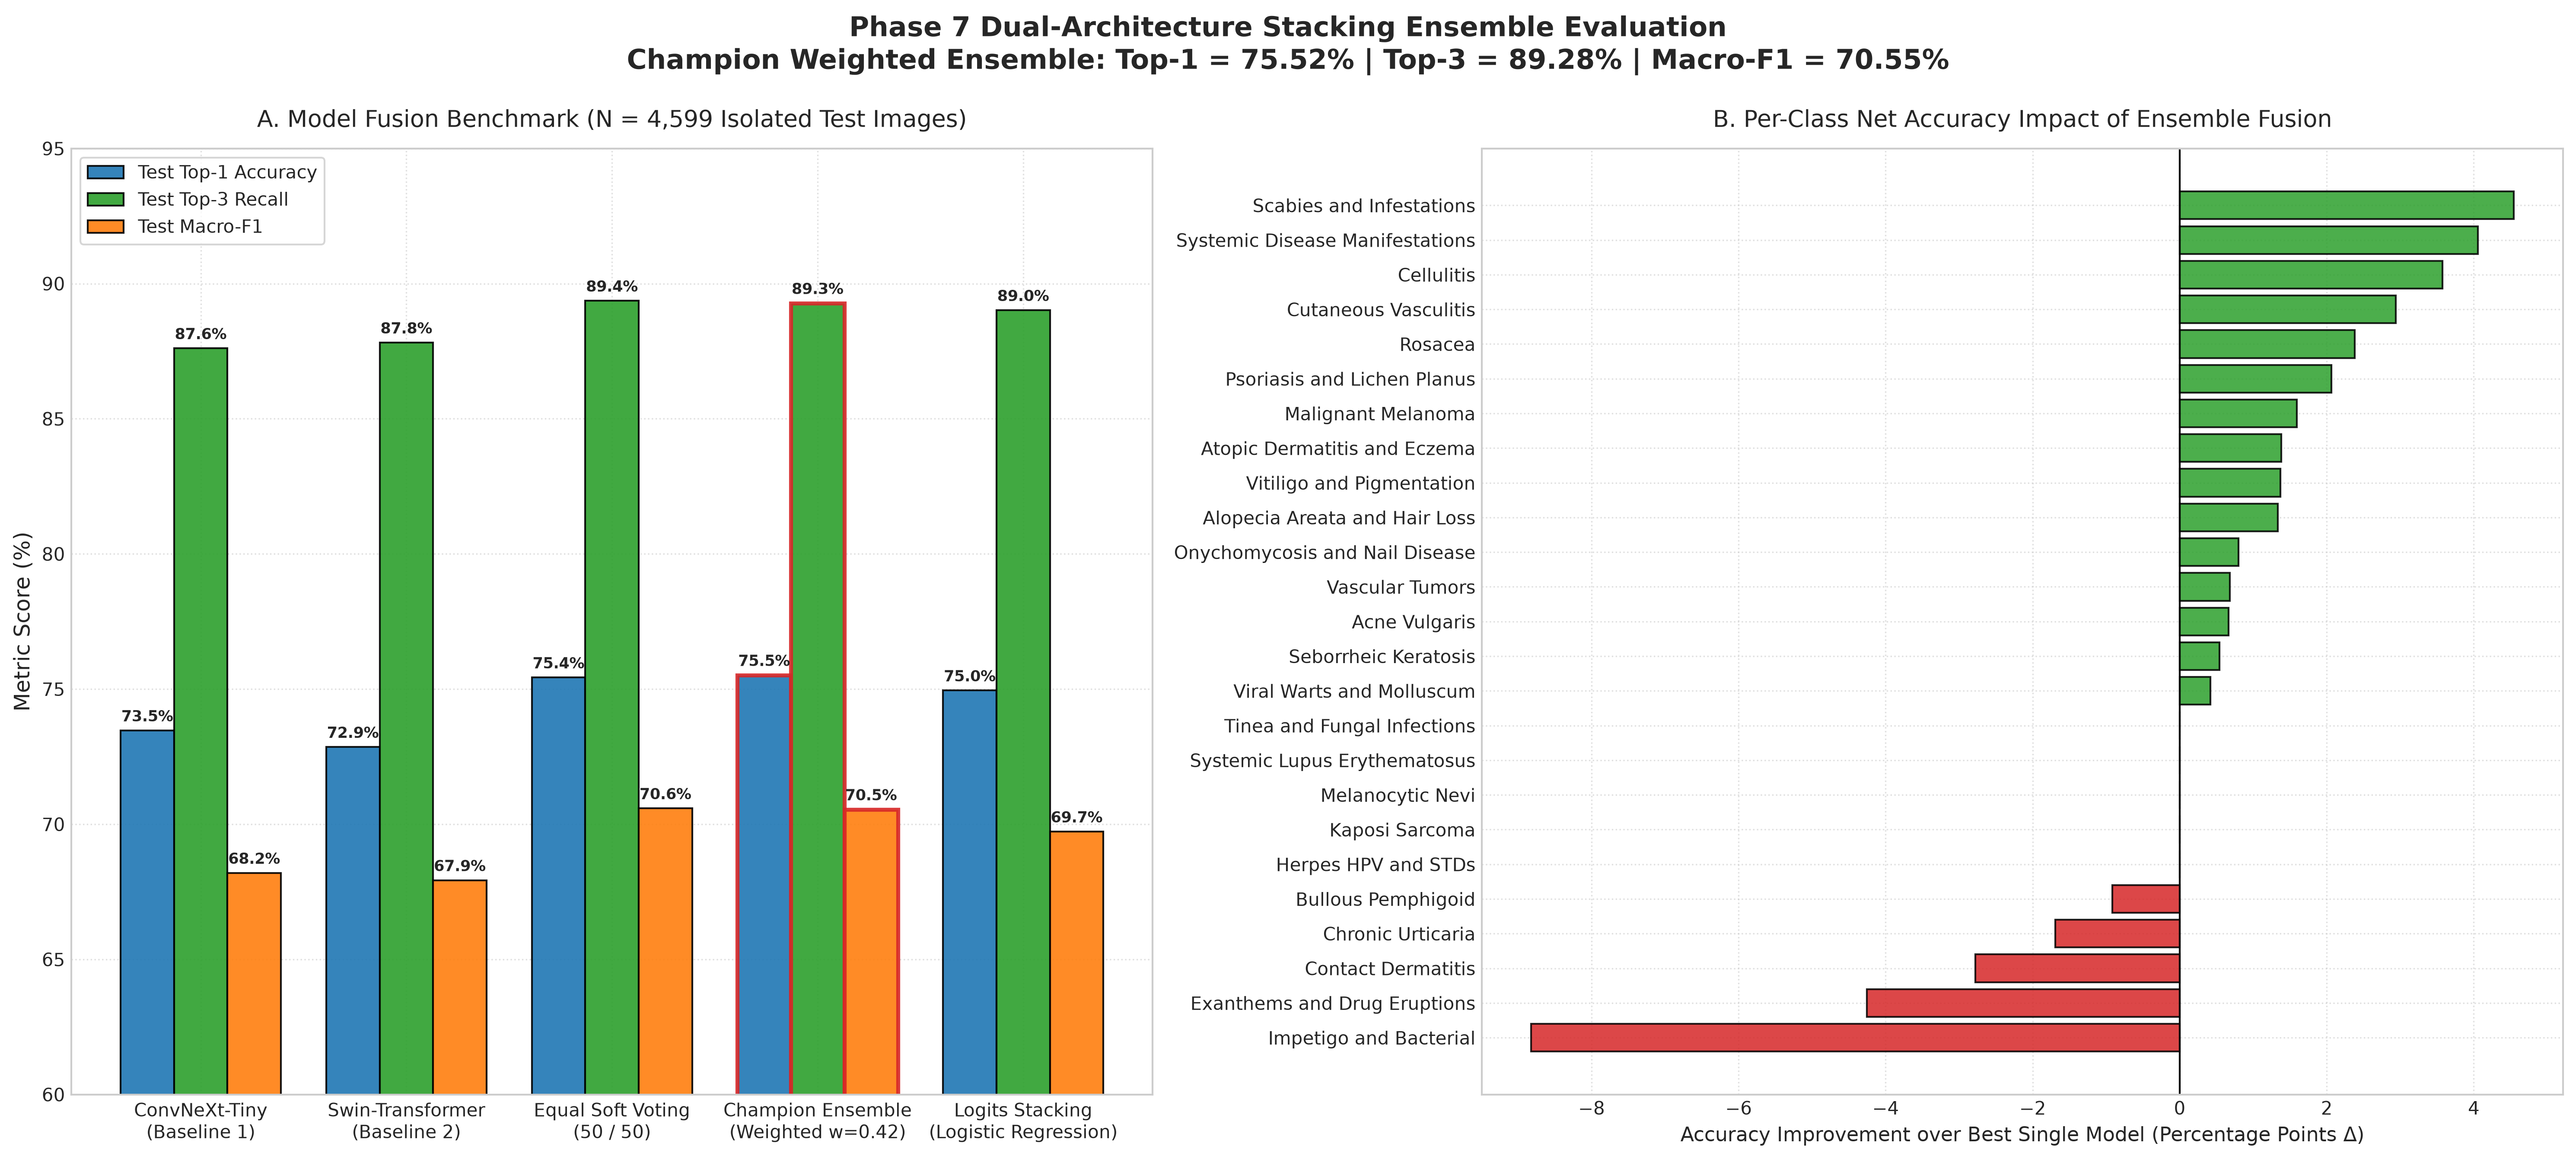

✓ Ensemble Comparative Figures Successfully Generated & Saved:
  --> c:\Users\kvcsu_ht23nk8\OneDrive\Desktop\all_Projects\BTech_Project\skin-disease\BTech_Project\results\plots\ensemble\01_ensemble_performance_comparison.png
Ready for Cell 5: Champion Ensemble Confusion Matrix & Acuity Tier Audit.


In [4]:
# ==============================================================================
# CELL 4: PUBLICATION VISUALIZATIONS (ENSEMBLE COMPARISON & PER-CLASS GAINS)
# ==============================================================================
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# ------------------------------------------------------------------------------
# 1. Plotting Configuration
# ------------------------------------------------------------------------------
plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")
plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 11,
    "axes.titlesize": 13,
    "axes.labelsize": 11,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "figure.titlesize": 16,
    "lines.linewidth": 2.0
})

fig, axes = plt.subplots(1, 2, figsize=(20, 9), dpi=300)

# ------------------------------------------------------------------------------
# Panel A: Strategy Benchmark Comparison (Top-1, Top-3, Macro-F1)
# ------------------------------------------------------------------------------
ax1 = axes[0]
plot_df = df_summary[df_summary["Strategy"].isin([
    "Single Model: ConvNeXt-Tiny",
    "Single Model: Swin-Transformer",
    "Strategy 1: Equal Soft Voting (50/50)",
    f"Strategy 2: Optimal Weighted Voting (w={best_w:.2f})",
    "Strategy 4: Logit-Level Stacking Meta-Learner"
])].copy()

labels_clean = [
    "ConvNeXt-Tiny\n(Baseline 1)",
    "Swin-Transformer\n(Baseline 2)",
    "Equal Soft Voting\n(50 / 50)",
    f"Champion Ensemble\n(Weighted w={best_w:.2f})",
    "Logits Stacking\n(Logistic Regression)"
]

x = np.arange(len(plot_df))
width = 0.26

rects1 = ax1.bar(x - width, plot_df["Test Top-1"], width, label="Test Top-1 Accuracy", color="#1f77b4", edgecolor="black", alpha=0.9)
rects2 = ax1.bar(x, plot_df["Test Top-3"], width, label="Test Top-3 Recall", color="#2ca02c", edgecolor="black", alpha=0.9)
rects3 = ax1.bar(x + width, plot_df["Test Macro-F1"], width, label="Test Macro-F1", color="#ff7f0e", edgecolor="black", alpha=0.9)

# Highlight Champion bar
champ_idx = 3
for bar_group in [rects1, rects2, rects3]:
    bar_group[champ_idx].set_linewidth(2.2)
    bar_group[champ_idx].set_edgecolor("#d62728")

ax1.set_ylabel("Metric Score (%)", fontsize=12)
ax1.set_title("A. Model Fusion Benchmark (N = 4,599 Isolated Test Images)", fontsize=13, pad=12)
ax1.set_xticks(x)
ax1.set_xticklabels(labels_clean, fontsize=10)
ax1.set_ylim(60, 95)
ax1.legend(loc="upper left", frameon=True, fontsize=10)
ax1.grid(True, linestyle=":", alpha=0.6)

# Annotate values above bars
def autolabel(rects):
    for rect in rects:
        height = rect.get_height()
        ax1.annotate(f"{height:.1f}%",
                    xy=(rect.get_x() + rect.get_width() / 2, height),
                    xytext=(0, 3), textcoords="offset points",
                    ha="center", va="bottom", fontsize=8.5, fontweight="bold")

autolabel(rects1)
autolabel(rects2)
autolabel(rects3)

# ------------------------------------------------------------------------------
# Panel B: Per-Class Accuracy Gain (Ensemble vs. Best Single Model)
# ------------------------------------------------------------------------------
ax2 = axes[1]

# Compute per-class accuracy for ConvNeXt, Swin, and Champion Ensemble
winning_probs = ensemble_payload["winning_test_probs"]
ens_preds = np.argmax(winning_probs, axis=1)
conv_preds = np.argmax(convnext_test_probs, axis=1)
swin_preds = np.argmax(swin_test_probs, axis=1)

class_gains = []
for cid in range(num_classes):
    mask = (test_targets == cid)
    c_total = mask.sum()
    if c_total == 0:
        continue
    c_acc_conv = (conv_preds[mask] == cid).mean() * 100.0
    c_acc_swin = (swin_preds[mask] == cid).mean() * 100.0
    best_single = max(c_acc_conv, c_acc_swin)
    
    c_acc_ens = (ens_preds[mask] == cid).mean() * 100.0
    gain = c_acc_ens - best_single
    
    c_name = ID_TO_LABEL[cid].replace("_", " ")
    class_gains.append({"Class": c_name, "Gain": gain, "Ens_Acc": c_acc_ens})

df_gains = pd.DataFrame(class_gains).sort_values("Gain", ascending=True)

colors = ["#2ca02c" if g >= 0 else "#d62728" for g in df_gains["Gain"]]
bars = ax2.barh(df_gains["Class"], df_gains["Gain"], color=colors, edgecolor="black", alpha=0.85)

ax2.axvline(0, color="black", linestyle="-", linewidth=1.0)
ax2.set_xlabel("Accuracy Improvement over Best Single Model (Percentage Points Δ)", fontsize=11)
ax2.set_title("B. Per-Class Net Accuracy Impact of Ensemble Fusion", fontsize=13, pad=12)
ax2.grid(True, linestyle=":", alpha=0.6)

# Suptitle & Save
plt.suptitle(
    "Phase 7 Dual-Architecture Stacking Ensemble Evaluation\n"
    f"Champion Weighted Ensemble: Top-1 = {winner['Test Top-1']}% | Top-3 = {winner['Test Top-3']}% | Macro-F1 = {winner['Test Macro-F1']}%",
    fontsize=15, y=0.99, fontweight="bold"
)

plt.tight_layout()
plots_dir = os.path.join(PROJECT_ROOT, "results", "plots", "ensemble")
os.makedirs(plots_dir, exist_ok=True)
plot_save_path = os.path.join(plots_dir, "01_ensemble_performance_comparison.png")
plt.savefig(plot_save_path, bbox_inches="tight")
plt.show()

print("=" * 80)
print(f"✓ Ensemble Comparative Figures Successfully Generated & Saved:")
print(f"  --> {plot_save_path}")
print("=" * 80)
print("Ready for Cell 5: Champion Ensemble Confusion Matrix & Acuity Tier Audit.")

  EVALUATING CHAMPION ENSEMBLE ON ISOLATED TEST HOLDOUT (N = 4,599)
✓ Champion Ensemble Test Top-1 Accuracy : 75.52%
✓ Champion Ensemble Test Top-3 Recall   : 89.28%
✓ Champion Ensemble Test Macro-F1       : 70.55%
✓ Champion Ensemble Test Weighted-F1    : 75.36%
--------------------------------------------------------------------------------
CLINICAL ACUITY TIER AUDIT (CHAMPION ENSEMBLE):
  • Tier 1 (N = 1,317): Accuracy = 69.78% | Macro-F1 = 26.00%
  • Tier 2 (N = 3,282): Accuracy = 77.82% | Macro-F1 = 51.12%

✓ Saved Champion Classification Report to: c:\Users\kvcsu_ht23nk8\OneDrive\Desktop\all_Projects\BTech_Project\skin-disease\BTech_Project\Models\ensemble\champion_ensemble_classification_report.csv

Critical High-Risk Conditions Audit Preview (Champion Ensemble):
                      precision  recall  f1-score  support
Malignant_Melanoma        0.802   0.819     0.811    564.0
Bullous_Pemphigoid        0.753   0.560     0.642    109.0
Cellulitis                0.364   0.286   

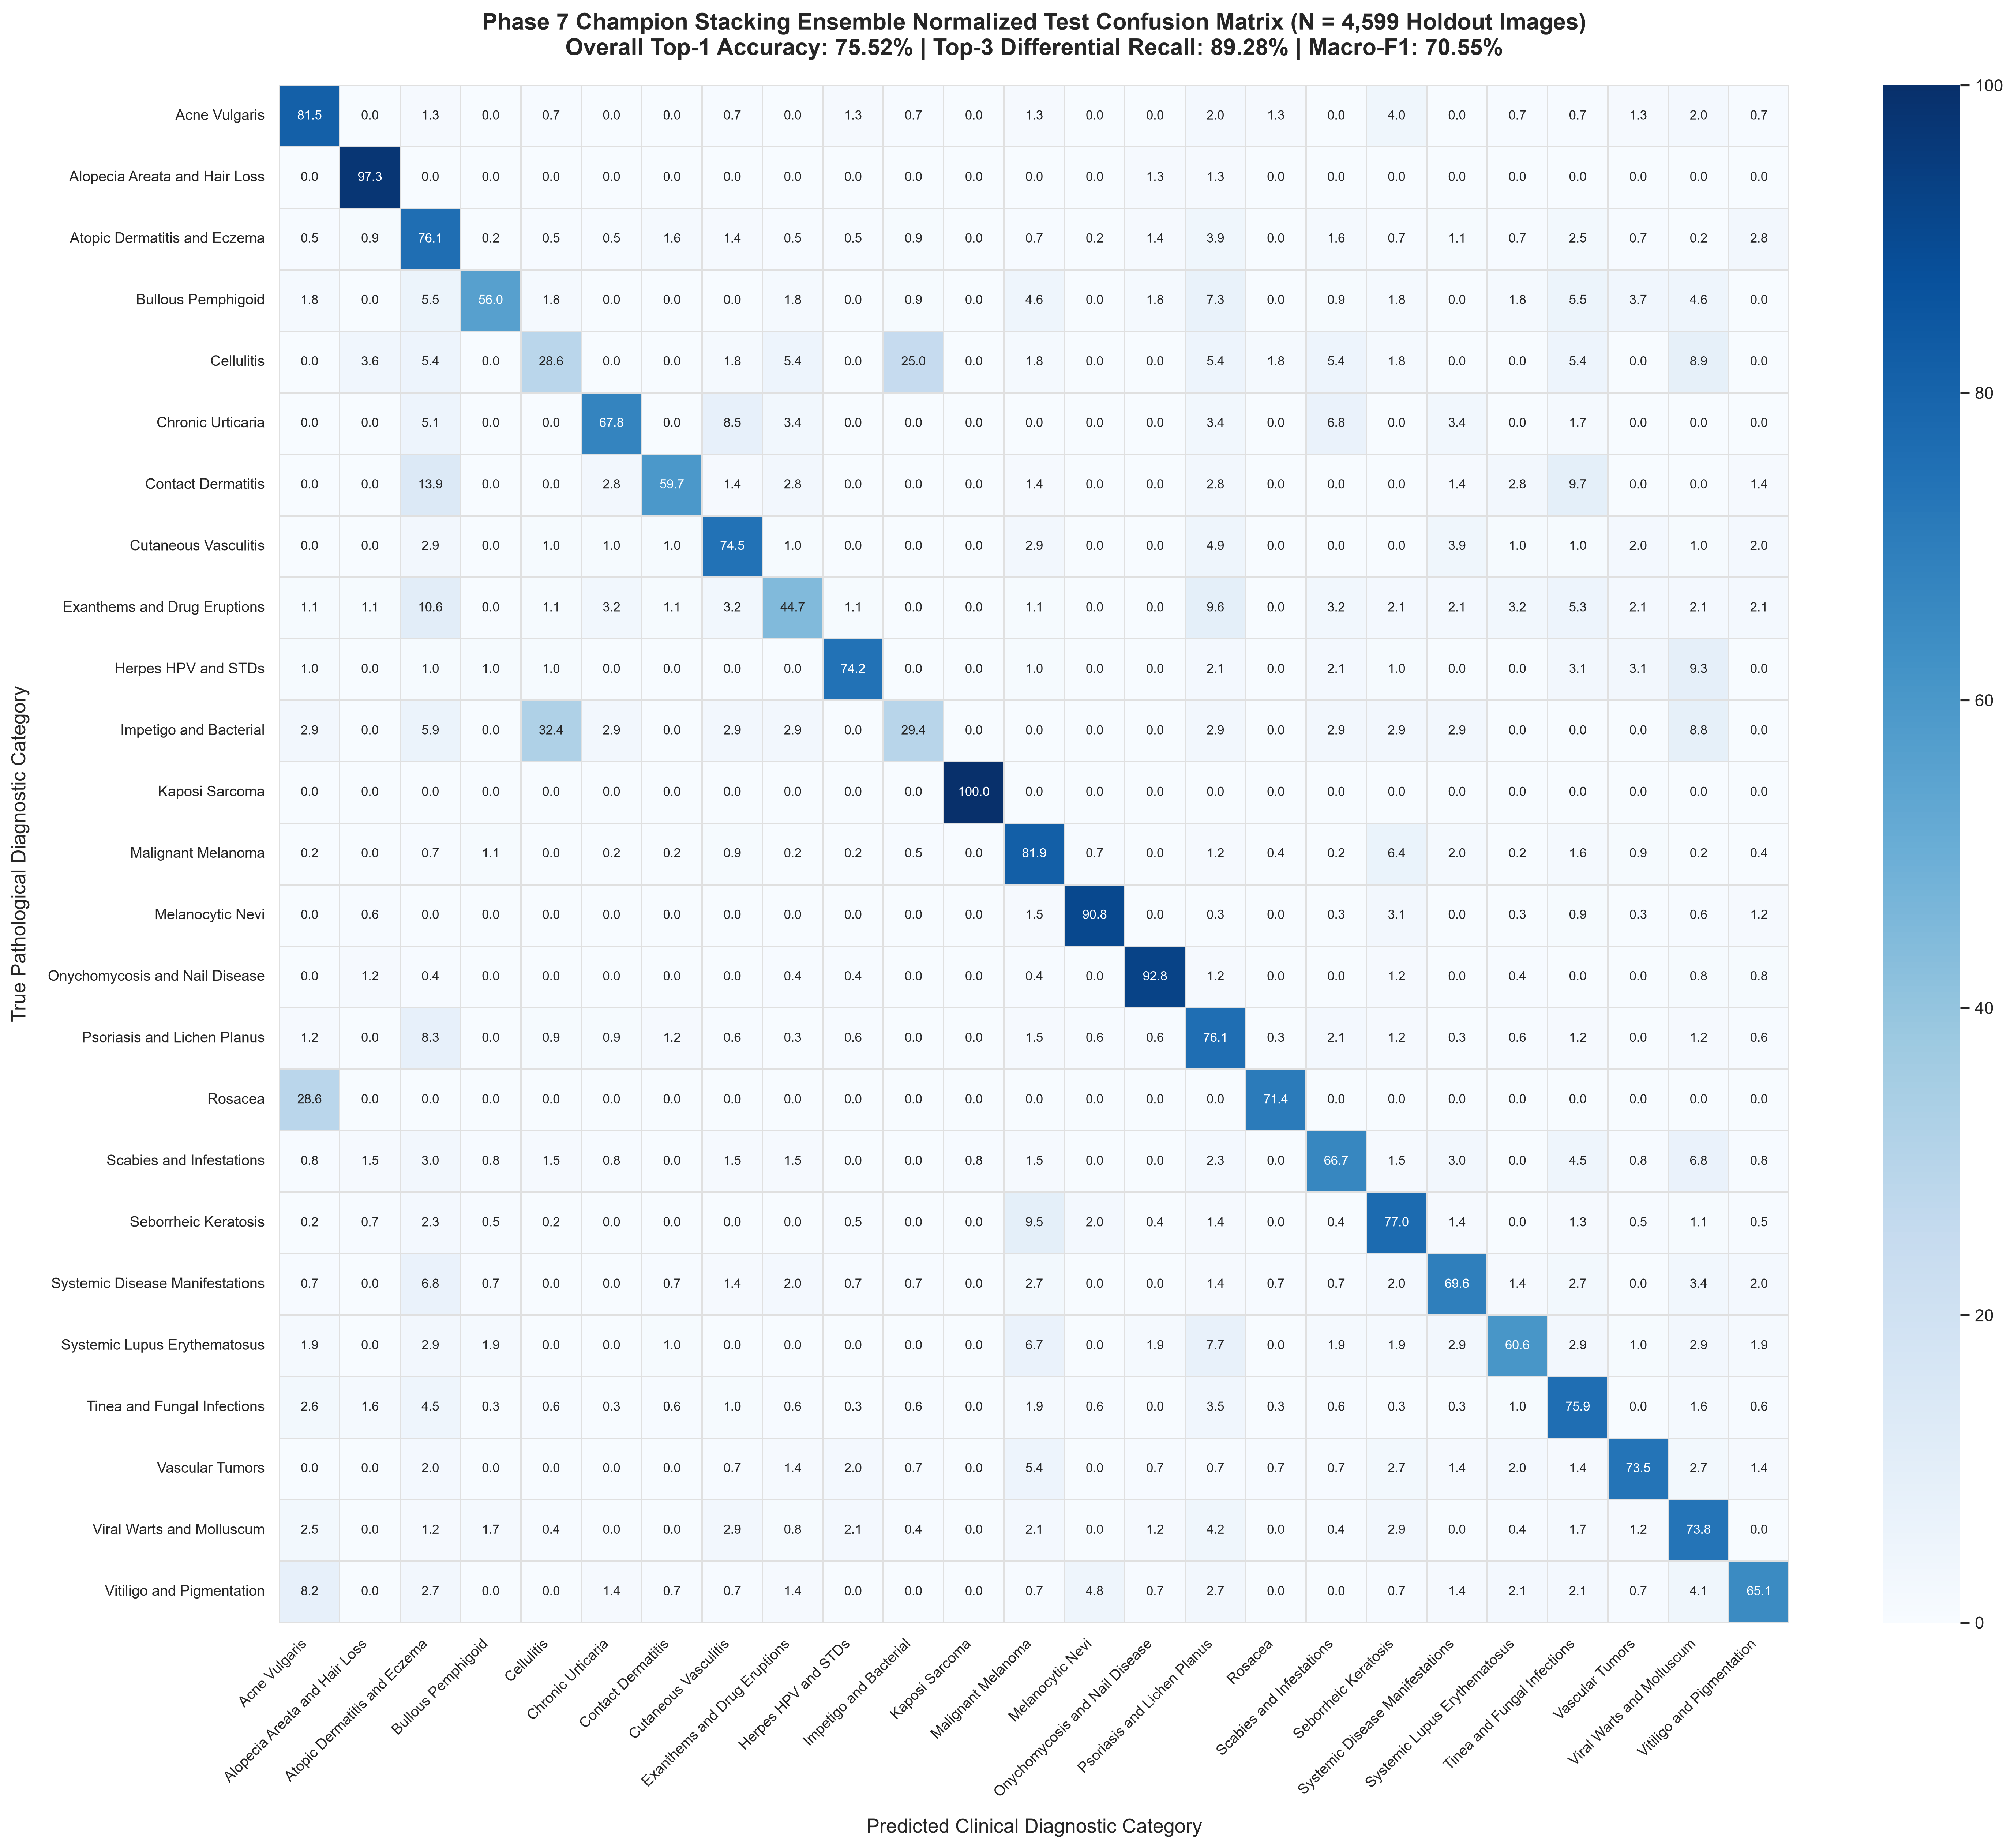

✓ Champion Ensemble Confusion Matrix Successfully Saved:
  --> c:\Users\kvcsu_ht23nk8\OneDrive\Desktop\all_Projects\BTech_Project\skin-disease\BTech_Project\results\plots\ensemble\02_champion_ensemble_confusion_matrix.png
PHASE 7 COMPLETE: Stacking Ensemble successfully validated!


In [5]:
# ==============================================================================
# CELL 5: CHAMPION ENSEMBLE CONFUSION MATRIX & CLINICAL ACUITY AUDIT
# ==============================================================================
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix, f1_score, accuracy_score

print("=" * 80)
print("  EVALUATING CHAMPION ENSEMBLE ON ISOLATED TEST HOLDOUT (N = 4,599)")
print("=" * 80)

# ------------------------------------------------------------------------------
# 1. Winning Ensemble Predictions & Class Names
# ------------------------------------------------------------------------------
winning_probs = ensemble_payload["winning_test_probs"]
ens_preds = np.argmax(winning_probs, axis=1)

target_names = [ID_TO_LABEL[i] for i in range(num_classes)]
clean_display_names = [name.replace("_", " ") for name in target_names]

# Global Metrics
final_acc = accuracy_score(test_targets, ens_preds) * 100.0
final_f1 = f1_score(test_targets, ens_preds, average="macro", zero_division=0) * 100.0
final_weighted_f1 = f1_score(test_targets, ens_preds, average="weighted", zero_division=0) * 100.0

top3_preds = np.argsort(winning_probs, axis=1)[:, -3:]
final_top3 = np.mean([test_targets[i] in top3_preds[i] for i in range(len(test_targets))]) * 100.0

print(f"✓ Champion Ensemble Test Top-1 Accuracy : {final_acc:.2f}%")
print(f"✓ Champion Ensemble Test Top-3 Recall   : {final_top3:.2f}%")
print(f"✓ Champion Ensemble Test Macro-F1       : {final_f1:.2f}%")
print(f"✓ Champion Ensemble Test Weighted-F1    : {final_weighted_f1:.2f}%")
print("-" * 80)

# ------------------------------------------------------------------------------
# 2. Clinical Acuity Tier Performance Audit
# ------------------------------------------------------------------------------
test_df = pd.DataFrame({
    "true_label": test_targets,
    "pred_label": ens_preds,
    "correct": (ens_preds == test_targets)
})
test_df["class_name"] = test_df["true_label"].map(ID_TO_LABEL)
test_df["tier"] = test_df["class_name"].map(CLASS_TIERS)

print("CLINICAL ACUITY TIER AUDIT (CHAMPION ENSEMBLE):")
for tier_name in sorted(test_df["tier"].dropna().unique()):
    tier_subset = test_df[test_df["tier"] == tier_name]
    t_acc = tier_subset["correct"].mean() * 100.0
    t_f1 = f1_score(tier_subset["true_label"], tier_subset["pred_label"], average="macro", zero_division=0) * 100.0
    print(f"  • {tier_name} (N = {len(tier_subset):,}): Accuracy = {t_acc:.2f}% | Macro-F1 = {t_f1:.2f}%")

# ------------------------------------------------------------------------------
# 3. Export Per-Class Classification Report
# ------------------------------------------------------------------------------
report_dict = classification_report(
    test_targets, 
    ens_preds, 
    target_names=target_names, 
    output_dict=True, 
    zero_division=0
)

df_report = pd.DataFrame(report_dict).transpose()
df_report["Tier"] = df_report.index.map(lambda x: CLASS_TIERS.get(x, ""))

report_save_path = os.path.join(ENSEMBLE_DIR, "champion_ensemble_classification_report.csv")
df_report.to_csv(report_save_path)
print(f"\n✓ Saved Champion Classification Report to: {report_save_path}")

# Preview Critical High-Risk Conditions
critical_classes = ["Malignant_Melanoma", "Bullous_Pemphigoid", "Cellulitis", "Kaposi_Sarcoma", "Cutaneous_Vasculitis"]
preview_df = df_report.loc[[c for c in critical_classes if c in df_report.index], ["precision", "recall", "f1-score", "support"]]
print("\nCritical High-Risk Conditions Audit Preview (Champion Ensemble):")
print(preview_df.round(3).to_string())

# ------------------------------------------------------------------------------
# 4. Normalized 25-Class Confusion Matrix Heatmap
# ------------------------------------------------------------------------------
cm = confusion_matrix(test_targets, ens_preds, normalize="true") * 100.0
cm_plot_path = os.path.join(PLOTS_DIR, "02_champion_ensemble_confusion_matrix.png")

plt.figure(figsize=(20, 17), dpi=300)
sns.set_theme(style="white")

ax = sns.heatmap(
    cm, 
    annot=True, 
    fmt=".1f", 
    cmap="Blues", 
    cbar=True,
    xticklabels=clean_display_names, 
    yticklabels=clean_display_names,
    annot_kws={"size": 8.5},
    linewidths=0.5,
    linecolor="#e0e0e0"
)

plt.title(
    f"Phase 7 Champion Stacking Ensemble Normalized Test Confusion Matrix (N = {len(test_targets):,} Holdout Images)\n"
    f"Overall Top-1 Accuracy: {final_acc:.2f}% | Top-3 Differential Recall: {final_top3:.2f}% | Macro-F1: {final_f1:.2f}%",
    fontsize=15, 
    pad=20, 
    fontweight="bold"
)
plt.xlabel("Predicted Clinical Diagnostic Category", fontsize=13, labelpad=12)
plt.ylabel("True Pathological Diagnostic Category", fontsize=13, labelpad=12)
plt.xticks(rotation=45, ha="right", fontsize=9.5)
plt.yticks(rotation=0, fontsize=9.5)

plt.tight_layout()
plt.savefig(cm_plot_path, bbox_inches="tight")
plt.show()

print("=" * 80)
print(f"✓ Champion Ensemble Confusion Matrix Successfully Saved:")
print(f"  --> {cm_plot_path}")
print("=" * 80)
print("PHASE 7 COMPLETE: Stacking Ensemble successfully validated!")